<a href="https://colab.research.google.com/github/yousefkoriem/Computer-Vision-Lab/blob/main/K_means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [44]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = [8, 6]
plt.rcParams['figure.dpi'] = 100

,Feature 1,Feature 2,True Cluster
0,4.627632,1.075915,1
1,1.932565,5.601569,4
2,0.741996,5.033909,4
3,1.398611,0.948782,1
4,-8.750419,-7.231623,2


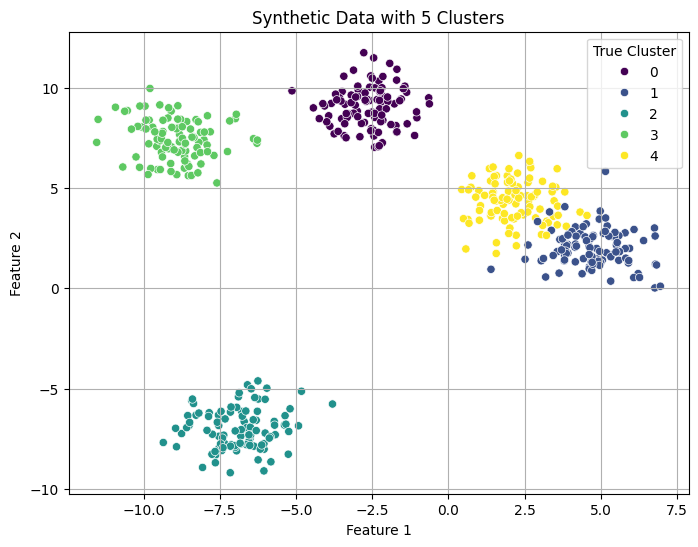

In [45]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=500, centers=5, cluster_std=1.0, random_state=42)

df_synthetic = pd.DataFrame(X, columns=['Feature 1', 'Feature 2'])
df_synthetic['True Cluster'] = y

display(df_synthetic.head())

plt.figure()
sns.scatterplot(data=df_synthetic, x='Feature 1', y='Feature 2', hue='True Cluster', palette='viridis', legend='full')
plt.title('Synthetic Data with 5 Clusters')
plt.grid(True)
plt.show()

In [46]:
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
k_range = range(2, 10)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X, kmeans.labels_))

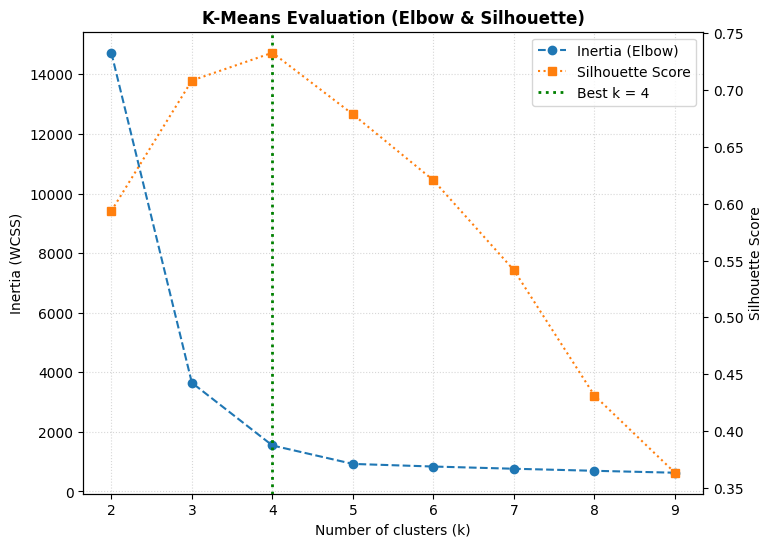

In [47]:
plt.figure()
ax1 = plt.gca()
ax1.set_xlabel('Number of clusters (k)')
ax1.set_ylabel('Inertia (WCSS)')
line1 = ax1.plot(k_range, inertias, marker='o',color='tab:blue', linestyle='--', label='Inertia (Elbow)')
ax1.tick_params(axis='y')
ax1.set_xticks(k_range)
ax1.grid(True, linestyle=':', alpha=0.5)

ax2 = ax1.twinx()
ax2.set_ylabel('Silhouette Score')
line2 = ax2.plot(k_range, silhouette_scores, marker='s',color='tab:orange', linestyle='dotted', label='Silhouette Score')
ax2.tick_params(axis='y')

vline = ax1.axvline(x=4, color='green', linestyle=':', linewidth=2, label='Best k = 4')

lines = line1 + line2 + [vline]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

plt.title('K-Means Evaluation (Elbow & Silhouette)', fontweight='bold')
plt.show()

In [48]:
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
y_kmeans = kmeans_final.fit_predict(X)
centroids = kmeans_final.cluster_centers_

y_kmeans, centroids

(array([2, 2, 2, 2, 1, 2, 1, 2, 0, 0, 2, 2, 2, 2, 3, 3, 2, 3, 1, 2, 2, 3,
        1, 3, 0, 3, 0, 3, 1, 2, 0, 0, 0, 2, 2, 0, 3, 2, 3, 0, 3, 2, 0, 3,
        0, 1, 0, 3, 1, 1, 1, 0, 2, 2, 2, 2, 2, 3, 3, 1, 1, 0, 2, 1, 0, 2,
        2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 3, 1, 1, 0, 2, 3, 1, 3, 2, 2,
        0, 2, 2, 1, 2, 1, 0, 2, 0, 1, 2, 2, 2, 2, 0, 2, 0, 1, 1, 1, 1, 1,
        2, 0, 2, 2, 1, 2, 3, 3, 1, 2, 3, 2, 2, 2, 2, 1, 0, 2, 1, 2, 2, 3,
        2, 3, 2, 3, 1, 2, 2, 2, 1, 1, 3, 1, 1, 3, 2, 1, 3, 2, 3, 2, 0, 0,
        0, 3, 2, 2, 1, 0, 2, 0, 1, 3, 3, 1, 3, 2, 2, 3, 2, 2, 3, 2, 1, 2,
        0, 0, 1, 2, 0, 0, 1, 2, 3, 0, 1, 0, 0, 2, 2, 2, 2, 0, 3, 3, 3, 2,
        3, 2, 2, 0, 0, 3, 2, 0, 0, 3, 2, 2, 1, 2, 3, 2, 2, 2, 3, 3, 1, 0,
        0, 3, 0, 2, 0, 2, 2, 0, 3, 2, 2, 0, 0, 2, 1, 2, 3, 1, 0, 1, 3, 3,
        0, 1, 2, 2, 1, 3, 0, 2, 2, 1, 2, 0, 1, 0, 2, 2, 0, 2, 2, 2, 0, 2,
        0, 3, 1, 2, 0, 2, 3, 0, 0, 2, 2, 0, 0, 0, 2, 2, 3, 0, 1, 2, 0, 3,
        2, 1, 2, 2, 1, 3, 0, 0, 2, 3, 

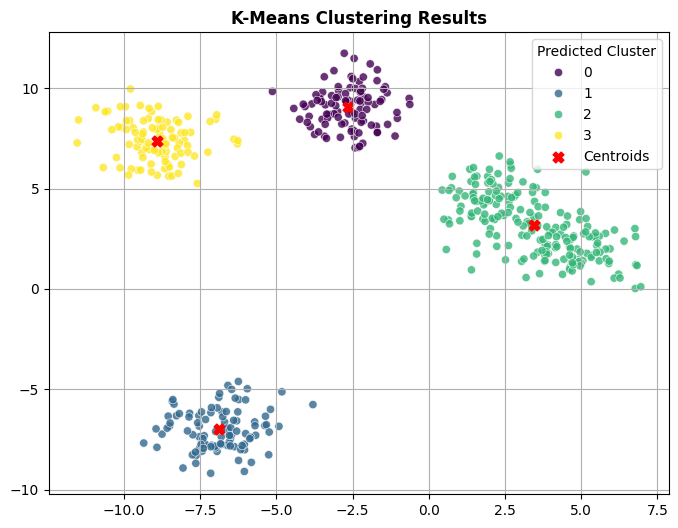

In [49]:
plt.figure()
sns.scatterplot(
    x=X[:, 0], y=X[:, 1], hue=y_kmeans, palette='viridis', legend='full', alpha=0.8
)
plt.scatter(
    centroids[:, 0], centroids[:, 1], color='red', marker='X', s=60, label='Centroids'
)

plt.title('K-Means Clustering Results', fontweight='bold')
plt.legend(title='Predicted Cluster')
plt.grid(True)
plt.show()